<a href="https://colab.research.google.com/github/donggeunlee77/MONAI-tutorial-exercise/blob/main/MONAI%20-%202D%20classification%20tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!python -c "import monai" || pip install -q "monai-weekly[pillow, tqdm]"
!python -c "import matplotlib" || pip install -q matplotlib
%matplotlib inline

Traceback (most recent call last):
  File "<string>", line 1, in <module>
    import monai
ModuleNotFoundError: No module named 'monai'


이거는 기본설정. 에러 일부 떠도 괜춘함

In [2]:
import os
import shutil
import tempfile
import matplotlib.pyplot as plt
import PIL     ## PIL: Python Imaging Library의 약자로, 이미지 파일을 읽고 변환하는 기능을 제공해. 현재는 Pillow라는 라이브러리로 유지되고 있어.
import torch
from torch.utils.tensorboard import SummaryWriter   ## TensorBoard에 학습 결과 기록
import numpy as np
from sklearn.metrics import classification_report   ## 분류 모델의 성능 평가

from monai.apps import download_and_extract
from monai.config import print_config
from monai.data import decollate_batch, DataLoader
from monai.metrics import ROCAUCMetric
from monai.networks.nets import DenseNet121
from monai.transforms import (
    Activations,
    EnsureChannelFirst,
    AsDiscrete,
    Compose,
    LoadImage,
    RandFlip,
    RandRotate,
    RandZoom,
    ScaleIntensity,
)

from monai.utils import set_determinism

print_config()


MONAI version: 1.7.dev2645
Numpy version: 2.4.6
Pytorch version: 2.14.1+cu130
MONAI flags: HAS_EXT=False, USE_COMPILED=False, USE_META_DICT=False
MONAI rev id: ed1d0c3cb86b2cfe223a7c845bec698dedbfa614
MONAI __file__: /usr/local/lib/python3.13/dist-packages/monai/__init__.py

Optional dependencies:
Pytorch Ignite version: NOT INSTALLED or UNKNOWN VERSION.
ITK version: NOT INSTALLED or UNKNOWN VERSION.
Nibabel version: 5.4.2
scikit-image version: 0.25.2
scipy version: 1.16.3
Pillow version: 11.3.0
Tensorboard version: 2.21.0
gdown version: 5.2.2
TorchVision version: 0.29.1+cu130
tqdm version: 4.67.3
lmdb version: NOT INSTALLED or UNKNOWN VERSION.
psutil version: 5.9.5
pandas version: 2.2.3
einops version: 0.8.2
transformers version: 5.22.1
mlflow version: NOT INSTALLED or UNKNOWN VERSION.
pynrrd version: NOT INSTALLED or UNKNOWN VERSION.
clearml version: NOT INSTALLED or UNKNOWN VERSION.

For details about installing the optional dependencies, please visit:
    https://monai.readthedocs.

classification_report : 분류모델의 성능평가

출력되는 주요 지표는 다음과 같아.

Precision	: 양성이라고 예측한 것 중 실제 양성 비율

Recall :	실제 양성 중 모델이 찾아낸 비율

F1-score:	Precision과 Recall의 조화평균

Support	: 해당 클래스의 실제 데이터 수

MONAI 모듈	기능

download_and_extract :	데이터셋 다운로드 및 압축 해제

print_config :	MONAI 및 관련 환경 정보 출력

decollate_batch	: Batch 데이터를 개별 데이터로 분리

DataLoader :	학습 데이터를 Batch 단위로 공급

ROCAUCMetric	: ROC-AUC 계산

DenseNet121 :	DenseNet121 신경망 모델

MONAI.transform : 전처리와 데이터 증강을 담당함.

- LoadImage	이미지 로딩
- EnsureChannelFirst	Channel 차원을 첫 번째 위치로 정렬
- Compose	여러 전처리 과정을 하나로 연결
- ScaleIntensity	영상 밝기값 정규화
- RandFlip	무작위 좌우 또는 상하 반전
- RandRotate	무작위 회전
- RandZoom	무작위 확대 및 축소
- Activations	Softmax, Sigmoid 등의 활성화 함수 적용
- AsDiscrete	확률 또는 예측값을 이산적인 클래스로 변환


set_determinism : 재현가능한 실험을 위한 함수. Random seed 설정

print_config()는 현재 설치된 MONAI, PyTorch, CUDA 등의 버전과 환경 정보를 출력해.

In [3]:
## Setup data directory
## 환경변수에 지정된 데이터 저장 경로가 있으면 그곳을 사용하고, 없으면 임시 폴더를 만들어 사용하겠다는 것
## You can specify a directory with the MONAI_DATA_DIRECTORY environment variable.

directory = os.environ.get("MONAI_DATA_DIRECTORY")  ## MONAI_DATA_DIRECTORY 환경변수가 설정돼있으면 그걸 반환, 없으면 None 반환
if directory is not None:
  os.makedirs(directory, exist_ok=True)
root_dir = tempfile.mkdtemp() if directory is None else directory  ## tempfile.mkdtemp()는 운영체제에서 임시 디렉터리를 생성하고 그 경로를 반환하는 함수야. 환경변수가 없으면 임시폴더경로, 있으면 지정된 데이터폴더경로를 root_dir로 지정하겠단 것
print(root_dir)

/tmp/tmplfuug4fg


In [4]:
## Download dataset : MedNIST

resource = "https://github.com/Project-MONAI/MONAI-extra-test-data/releases/download/0.8.1/MedNIST.tar.gz"
md5 = "0bc7306e7427e00ad1c5526a6677552d"

compressed_file = os.path.join(root_dir, "MedNIST.tar.gz")  ## 압축파일이 저장될 경로를 지정
data_dir = os.path.join(root_dir, "MedNIST")  ## 압축 해제후 데이터가 저장될 경로
if not os.path.exists(data_dir):
  download_and_extract(resource, compressed_file, root_dir, md5, "md5")   ## MedNIST 폴더가 존재하지 않는다면 다운로드 및 압축해제를 실행해라


MedNIST.tar.gz: 59.0MB [00:01, 58.5MB/s]                            


2026-11-11 00:32:55,939 - INFO - Verified 'MedNIST.tar.gz', md5: 0bc7306e7427e00ad1c5526a6677552d.
2026-11-11 00:32:55,940 - INFO - Downloaded: /tmp/tmplfuug4fg/MedNIST.tar.gz
2026-11-11 00:32:55,941 - INFO - Writing into directory: /tmp/tmplfuug4fg.


MD5는 Message Digest Algorithm 5의 약자야.

다운로드한 파일이 원본과 동일한지 확인하는 체크섬(checksum)이야.

예를 들어 다운로드 도중 파일이 손상되거나 일부 데이터가 변경되었다면 MD5 값이 달라질 수 있어.

즉, 데이터셋의 무결성을 확인하기 위한 장치야.

download_and_extract 함수
- 1번째 인자 : 다운로드할 인터넷 주소
- 2번째 인자 : 다운로드한 압축파일의 저장위치
- 3번째 인자 : 압축 해제할 위치
- 4번째 인자 : 파일 무결성 확인용 해시값
- 5번째 인자 : 사용할 체크섬 알고리즘

In [5]:
set_determinism(seed=0)

잠시 샛길. 아래에선 기본적인 폴더탐색 with chatGPT

In [ ]:
print(root_dir)
print(os.listdir(root_dir)) ## os.listdir(path)	는 해당 폴더 내부의 파일·폴더 목록을 나타내줌.
print(os.listdir(data_dir))
print(os.listdir(os.path.join(data_dir, "Hand")))

/tmp/tmp1kuazvzs
['MedNIST', 'MedNIST.tar.gz']
['Hand', 'AbdomenCT', 'ChestCT', 'BreastMRI', 'CXR', 'HeadCT', 'README.md']
['003798.jpeg', '009242.jpeg', '000857.jpeg', '001960.jpeg', '001929.jpeg', '003856.jpeg', '002617.jpeg', '001186.jpeg', '000777.jpeg', '003612.jpeg', '003834.jpeg', '005432.jpeg', '001869.jpeg', '003589.jpeg', '009442.jpeg', '002366.jpeg', '008421.jpeg', '003845.jpeg', '004880.jpeg', '005336.jpeg', '004815.jpeg', '002624.jpeg', '002141.jpeg', '007082.jpeg', '001143.jpeg', '002348.jpeg', '000576.jpeg', '003257.jpeg', '007635.jpeg', '008192.jpeg', '007354.jpeg', '008393.jpeg', '001232.jpeg', '003182.jpeg', '007052.jpeg', '006488.jpeg', '004453.jpeg', '004922.jpeg', '004492.jpeg', '004788.jpeg', '008620.jpeg', '009312.jpeg', '007401.jpeg', '009416.jpeg', '005966.jpeg', '006710.jpeg', '001552.jpeg', '003537.jpeg', '008365.jpeg', '004373.jpeg', '006949.jpeg', '007733.jpeg', '003623.jpeg', '000554.jpeg', '004518.jpeg', '006002.jpeg', '005007.jpeg', '002692.jpeg', '00312

In [ ]:
for class_name in os.listdir(data_dir):
  class_path = os.path.join(data_dir, class_name)
  if os.path.isdir(class_path):  ## 해당 경로가 디렉터리인지 확인
    images = os.listdir(class_path)
    print(f"{class_name}: {len(images)} images")

Hand: 10000 images
AbdomenCT: 10000 images
ChestCT: 10000 images
BreastMRI: 8954 images
CXR: 10000 images
HeadCT: 10000 images


/tmp/tmp1kuazvzs/MedNIST/ChestCT 003798.jpeg
/tmp/tmp1kuazvzs/MedNIST/ChestCT/003798.jpeg


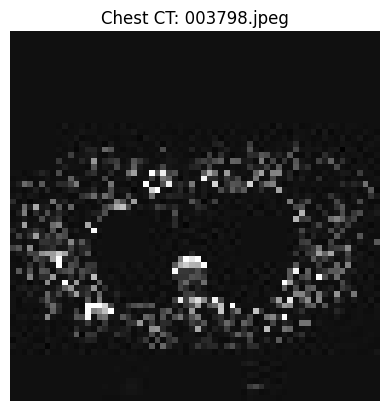

In [ ]:
##이미지 하나 열어보기

from PIL import Image
import matplotlib.pyplot as plt

class_path = os.path.join(data_dir, "ChestCT")
image_name = os.listdir(class_path)[0]
print(class_path, image_name)

image_path = os.path.join(class_path, image_name)
print(image_path)

img = Image.open(image_path)

plt.imshow(img, cmap='gray')
plt.title(f"Chest CT: {image_name}")
plt.axis('off')
plt.show()

자 다시 돌아와서

In [6]:
os.listdir(data_dir)

['HeadCT', 'BreastMRI', 'Hand', 'CXR', 'README.md', 'AbdomenCT', 'ChestCT']

In [12]:
class_names = sorted(x for x in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, x))) ## data_dir 폴더의 하위폴더 이름들을 알파벳순으로 정렬. data_dir 안에 바로 들어있는 파일이 있다면 제외하기 위해 isdir을 쓴것
num_class = len(class_names)
image_files = [
    [os.path.join(data_dir, class_names[i], x) for x in os.listdir(os.path.join(data_dir, class_names[i]))]
    for i in range(num_class)
] ## class_names 별 이미지 파일의 path list

num_each = [len(image_files[i]) for i in range(num_class)]
image_files_list = []
image_class = []

for i in range(num_class):
  image_files_list.extend(image_files[i])  ##image_file는 class_names 별로 있는데, 그걸 그냥 순서대로 한 리스트에 쭉 붙여넣은것인듯
  image_class.extend([i] * num_each[i])  ## Python에서 리스트에 숫자를 곱하면 해당 리스트가 숫자 횟수 만큼 반복돼. 즉 image_files_list 내부 각각 원소에 대응하는 class를 붙여준것
## extend()는 기존 리스트에 다른 리스트의 원소들을 하나씩 추가하는 함수야.
## print(image_files_list[0:5], image_class[0:5])

num_total = len(image_class)

image_width, image_height = PIL.Image.open(image_files_list[0]).size  ## 우항 PIL.Image.open(~).size가 기본적으로 (width, height) 형태로 반환해주므로

print(f"Total image count: {num_total}")
print(f"Image dimensions: {image_width} x {image_height}")
print(f"Label names: {class_names}")
print(f"Label count: {num_each}")

Total image count: 58954
Image dimensions: 64 x 64
Label names: ['AbdomenCT', 'BreastMRI', 'CXR', 'ChestCT', 'Hand', 'HeadCT']
Label count: [10000, 8954, 10000, 10000, 10000, 10000]


Nested List Comprehension
image_files = [
  [내부 반복문]
  외부 반복문
]
이 구조로, 외부 반복문은 각 클래스 폴더를 순회, 내부 반복문은 해당 클래스 폴더 안의 파일을 순회. 즉 클래스별로 파일 목록을 만드는 구조

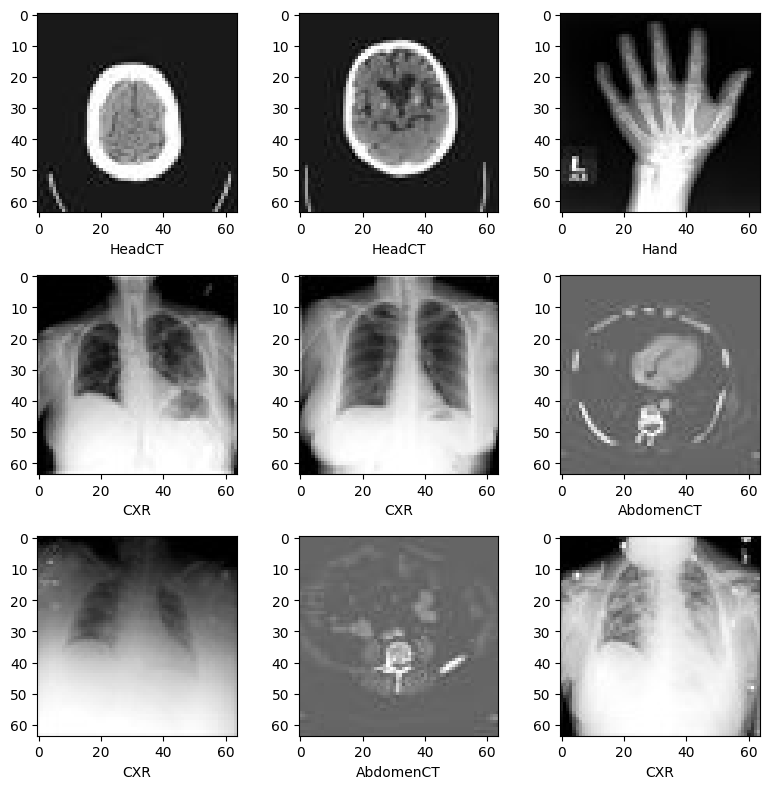

In [20]:
## Randomly pick images from the dataset to visualize and check

plt.subplots(3, 3, figsize=(8,8)) ##격자공간 준비
for i, k in enumerate(np.random.randint(num_total, size=9)): ## enumerate는 for 구문에서 index 와 원소를 함께 가져와줌.
  im = PIL.Image.open(image_files_list[k])
  arr = np.array(im) ## 이렇게 numpy array로 변환해야함!!
  plt.subplot(3, 3, i+1) ## 3×3 격자 중에서 몇 번째 위치에 이미지를 표시할 것인지 지정해. 위치번호는 1부터 시작하기 때문에 i+1 로 해줌
  plt.xlabel(class_names[image_class[k]])
  plt.imshow(arr, cmap='gray', vmin=0, vmax=255)
plt.tight_layout()
plt.show()



In [25]:
## Prepare training, validation and test data lists
## Randomly select 10% of the dataset as validation and 10% as test.

val_frac = 0.1
test_frac = 0.1
length = len(image_files_list)
indices = np.arange(length)  ## 0부터 length까지 1씩 늘어나는 배열 생성
np.random.shuffle(indices) ## indices는 인제 랜덤으로 셔플됨

test_split = int(test_frac * length)
test_indices = indices[:test_split]
val_split = int(val_frac * length) + test_split
val_indices = indices[test_split:val_split]
train_indices = indices[val_split:]

## 이까지는 랜덤숫자인 indices를 비율대로 순차적으로 잘라준것.

train_x = [image_files_list[i] for i in train_indices]
train_y = [image_class[i] for i in train_indices]
val_x = [image_files_list[i] for i in val_indices]
val_y = [image_class[i] for i in val_indices]
test_x = [image_files_list[i] for i in test_indices]
test_y = [image_class[i] for i in test_indices]

print(f"Training count : {len(train_x)}, Validation count : {len(val_x)}, Test count : {len(test_x)}")

Training count : 47164, Validation count : 5895, Test count : 5895


In [ ]:
## Define MONAI transforms, Dataset and Dataloader to pre-process data

